In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
import numpy as np
import nibabel as nib
import warnings
import copy
import torch
from torch.utils.data import Dataset
def get_slice_data(volume_data, seg_data, axis, slice_idx):
    
    if axis == 0:  
        vol_slice = volume_data[slice_idx, :, :]
        seg_slice = seg_data[slice_idx, :, :]
    elif axis == 1:  
        vol_slice = volume_data[:, slice_idx, :]
        seg_slice = seg_data[:, slice_idx, :]
    else:  
        vol_slice = volume_data[:, :, slice_idx]
        seg_slice = seg_data[:, :, slice_idx]
    
    vol_slice = np.squeeze(vol_slice)
    seg_slice = np.squeeze(seg_slice)
    
    vol_slice_rotated = np.rot90(vol_slice, k=1)
    seg_slice_rotated = np.rot90(seg_slice, k=1)
    
    return vol_slice_rotated, seg_slice_rotated

def pad_slice(vol_slice, seg_slice, target_dims=(256, 256)):
    
    h, w = vol_slice.shape
    th, tw = target_dims

    pad_h_top = (th - h) // 2
    pad_h_bottom = th - h - pad_h_top
    pad_w_left = (tw - w) // 2
    pad_w_right = tw - w - pad_w_left

    padding = ((max(0, pad_h_top), max(0, pad_h_bottom)), 
               (max(0, pad_w_left), max(0, pad_w_right)))

    vol_padded = np.pad(vol_slice, padding, mode='constant', constant_values=0)
    seg_padded = np.pad(seg_slice, padding, mode='constant', constant_values=0)
    
    vol_padded = vol_padded[:th, :tw]
    seg_padded = seg_padded[:th, :tw]

    return vol_padded, seg_padded

class IBSRPatchDataset(Dataset):
    
    
    def __init__(self, volume_files, segmentation_files):
        self.patches = []
        self.masks = []
        self.patch_size = 128
        self.target_dims = (256, 256)
        self.slice_start = 10
        self.slice_stride = 3
        self.num_slices_to_extract = 48

        print("Loading and processing dataset (with rotation)...")
        for vol_path, seg_path in zip(volume_files, segmentation_files):
            try:
                vol_img = nib.load(vol_path)
                seg_img = nib.load(seg_path)

                vol_data = vol_img.get_fdata()
                seg_data = seg_img.get_fdata()

                for axis in range(3):
                    num_slices_in_axis = vol_data.shape[axis]
                    
                    slice_indices = list(range(
                        self.slice_start, 
                        num_slices_in_axis, 
                        self.slice_stride
                    ))[:self.num_slices_to_extract]

                    for slice_idx in slice_indices:
                        vol_slice_rotated, seg_slice_rotated = get_slice_data(vol_data, seg_data, axis, slice_idx)
                        
                        vol_padded, seg_padded = pad_slice(vol_slice_rotated, seg_slice_rotated, self.target_dims)
                        
                        for x in [0, self.patch_size]:
                            for y in [0, self.patch_size]:
                                vol_patch = vol_padded[x : x + self.patch_size, y : y + self.patch_size]
                                seg_patch = seg_padded[x : x + self.patch_size, y : y + self.patch_size]
                                
                                self.patches.append(vol_patch)
                                self.masks.append(seg_patch)
            except Exception as e:
                warnings.warn(f"Warning: Skipping file {vol_path} due to error: {e}")

        print(f"Dataset loaded. Total patches: {len(self.patches)}")

    def __len__(self):
        return len(self.patches)

    def __getitem__(self, idx):
        vol_patch = self.patches[idx].astype(np.float32)
        seg_patch = self.masks[idx].astype(np.int64)
        
        vol_patch_normalized = vol_patch

        
        vol_tensor = torch.tensor(vol_patch_normalized, dtype=torch.float32).unsqueeze(0)
        mask_tensor = torch.tensor(seg_patch, dtype=torch.long) 
        
        return vol_tensor, mask_tensor


In [21]:
!pip install gdown
!gdown --folder "https://drive.google.com/drive/folders/1eR-MM1yzrA86N7lAN7Pr3aPdXj0qnd5_"

Retrieving folder contents
Processing file 1Q37u5v3a01I7n_B0iFbFeZoVipvK4ccq IBSR_nifti_stripped.zip
Processing file 1ebbV0obAlUQHIy8zKt0RAygMqzt78Dd9 README.txt
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1Q37u5v3a01I7n_B0iFbFeZoVipvK4ccq
From (redirected): https://drive.google.com/uc?id=1Q37u5v3a01I7n_B0iFbFeZoVipvK4ccq&confirm=t&uuid=930ed7a5-5057-4fae-a6b2-032ae40b35c6
To: /kaggle/working/IBSR dataset Skull stripped/IBSR_nifti_stripped.zip
100%|██████████████████████████████████████| 77.6M/77.6M [00:01<00:00, 66.7MB/s]
Downloading...
From: https://drive.google.com/uc?id=1ebbV0obAlUQHIy8zKt0RAygMqzt78Dd9
To: /kaggle/working/IBSR dataset Skull stripped/README.txt
100%|██████████████████████████████████████| 20.9k/20.9k [00:00<00:00, 51.5MB/s]
Download completed


In [23]:
!unzip 'IBSR dataset Skull stripped/IBSR_nifti_stripped.zip'

Archive:  IBSR dataset Skull stripped/IBSR_nifti_stripped.zip
replace IBSR_nifti_stripped/.DS_Store? [y]es, [n]o, [A]ll, [N]one, [r]ename: ^C


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import torch

def collection_path(a):
    s = f'{a:02}'
    vol = f'./IBSR_nifti_stripped/IBSR_{s}/IBSR_{s}_ana_strip.nii.gz'
    seg = f'./IBSR_nifti_stripped/IBSR_{s}/IBSR_{s}_segTRI_ana.nii.gz'
    return [vol], [seg]

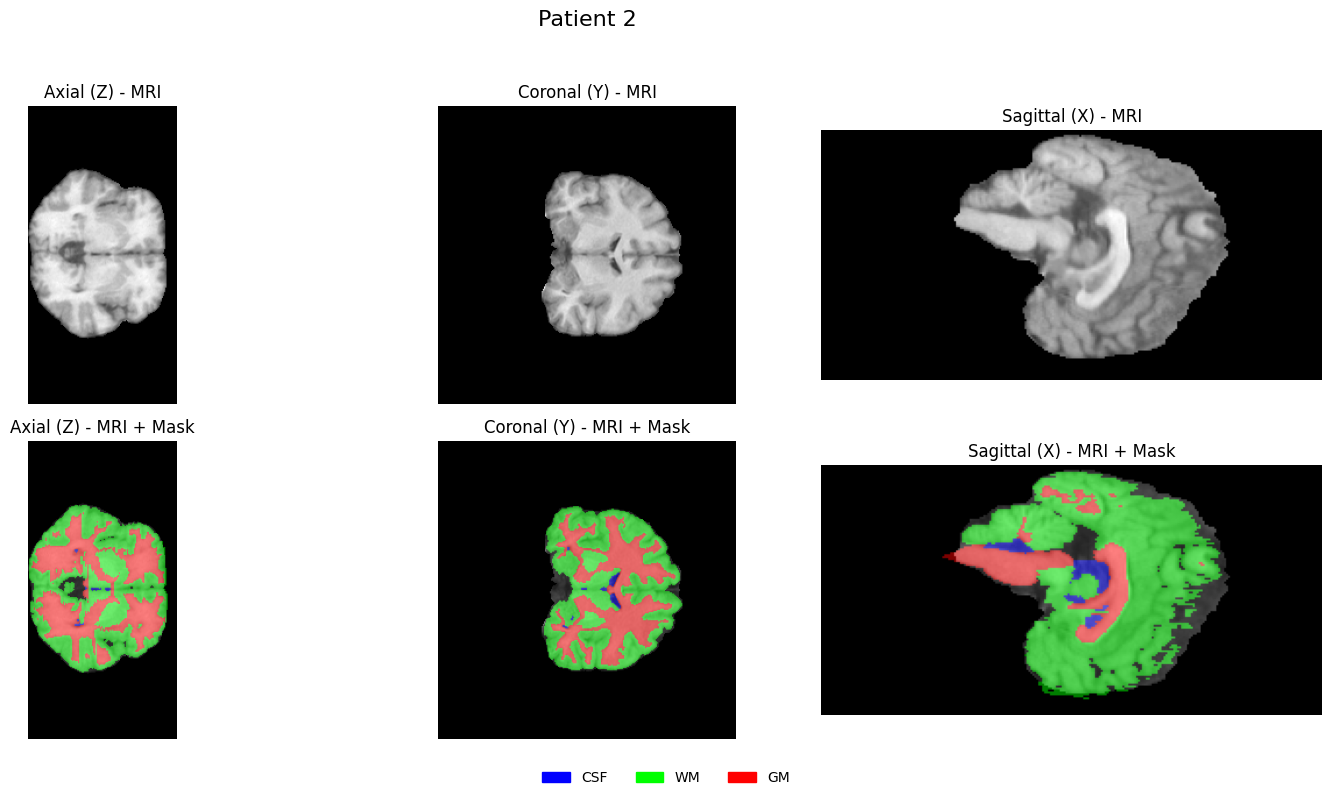

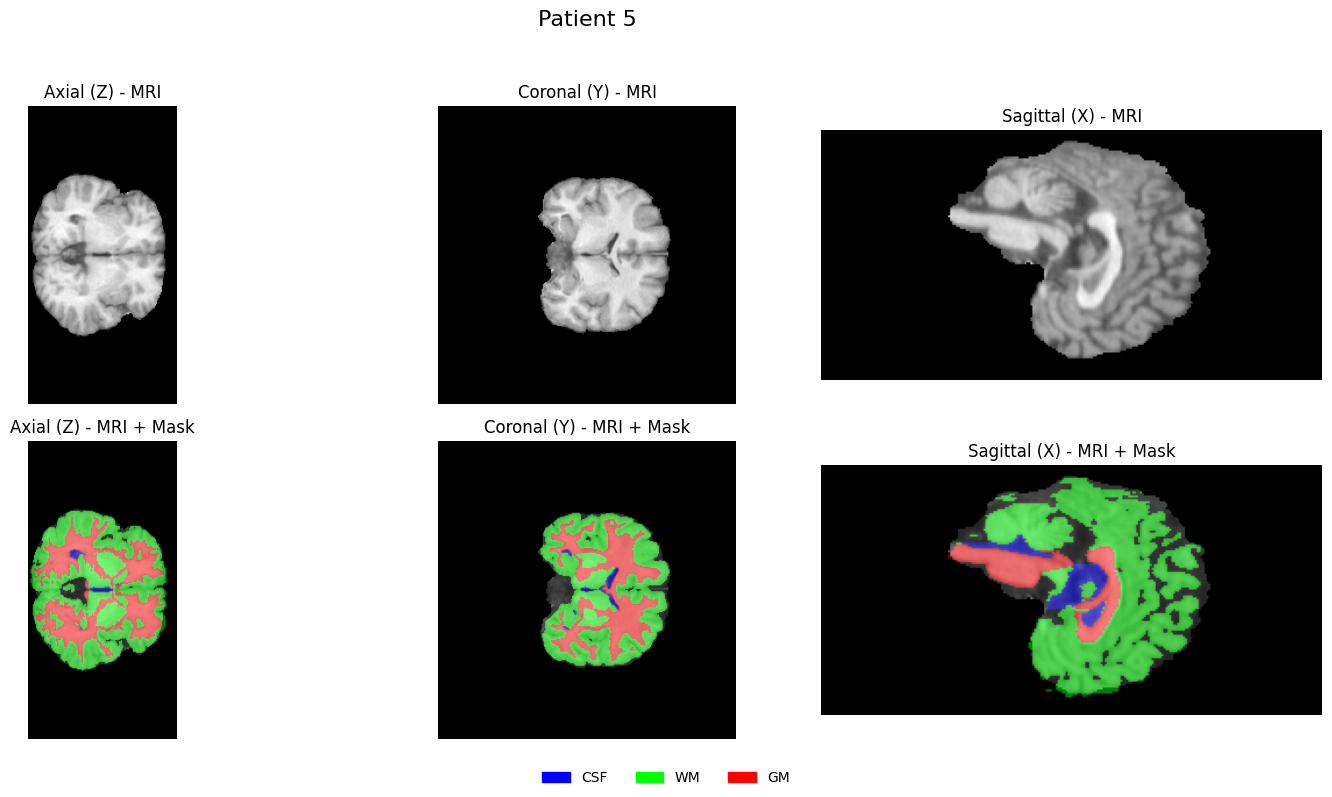

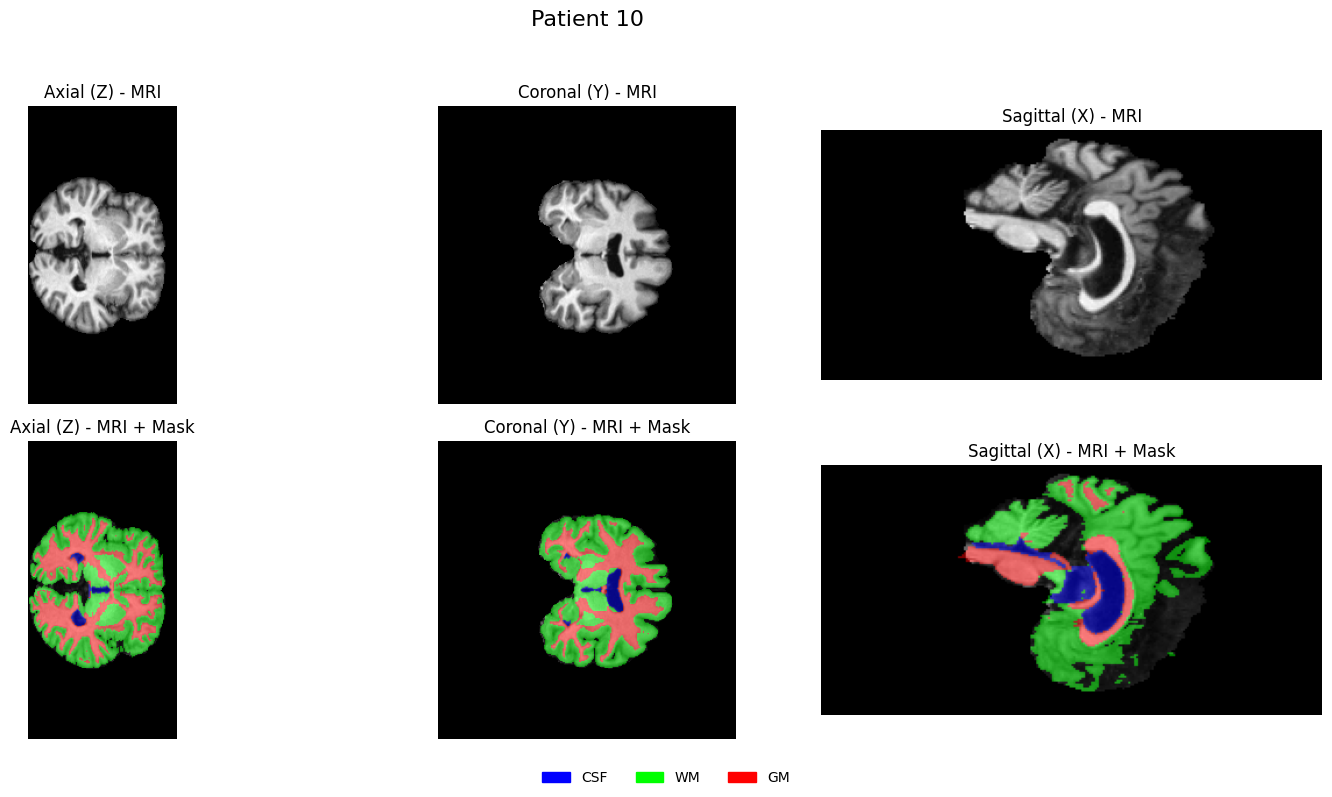

In [13]:
from matplotlib.patches import Patch

def plot_patients_3planes():

    CLASS_COLORS = {
        0: (0, 0, 0),   # Background
        1: (0, 0, 1),   # CSF
        2: (0, 1, 0),   # WM
        3: (1, 0, 0),   # GM
    }

    CLASS_NAMES = {
        0: 'BG',
        1: 'CSF',
        2: 'WM',
        3: 'GM'
    }

    def colorize_mask(mask):
        h, w = mask.shape
        rgb = np.zeros((h, w, 3))
        for cls, color in CLASS_COLORS.items():
            rgb[mask == cls] = color
        return rgb

    patients = [2, 5, 10]

    for patient_id in patients:
        vol_path, seg_path = collection_path(patient_id)
        vol_path = vol_path[0]
        seg_path = seg_path[0]

        volume = nib.load(vol_path).get_fdata()
        segmentation = nib.load(seg_path).get_fdata().astype(np.int32)

        volume = np.squeeze(volume)
        segmentation = np.squeeze(segmentation)

        sx, sy, sz = volume.shape
        slices = {
            'Axial (Z)':    (slice(None), slice(None), sz // 2),
            'Coronal (Y)': (slice(None), sy // 2, slice(None)),
            'Sagittal (X)':(sx // 2, slice(None), slice(None)),
        }

        fig, axes = plt.subplots(2, 3, figsize=(15, 8))
        fig.suptitle(f'Patient {patient_id}', fontsize=16)

        for col, (title, slc) in enumerate(slices.items()):
            vol_slice = np.squeeze(volume[slc])
            seg_slice = np.squeeze(segmentation[slc])

            axes[0, col].imshow(vol_slice, cmap='gray')
            axes[0, col].set_title(f'{title} - MRI')
            axes[0, col].axis('off')

            axes[1, col].imshow(vol_slice, cmap='gray')
            axes[1, col].imshow(colorize_mask(seg_slice), alpha=0.5)
            axes[1, col].set_title(f'{title} - MRI + Mask')
            axes[1, col].axis('off')

        legend_patches = [
            Patch(color=CLASS_COLORS[c], label=CLASS_NAMES[c])
            for c in CLASS_COLORS if c != 0
        ]

        fig.legend(
            handles=legend_patches,
            loc='lower center',
            ncol=4,
            frameon=False
        )

        plt.tight_layout(rect=[0, 0.05, 1, 0.95])
        plt.show()
plot_patients_3planes()

In [26]:
vol_path, seg_path = collection_path(1)
vol_path = vol_path[0]
seg_path = seg_path[0]

print(nib.load(vol_path).get_fdata().shape)
print(nib.load(seg_path).get_fdata().shape)


(256, 128, 256, 1)
(256, 128, 256, 1)


Loading and processing dataset (with rotation)...
Dataset loaded. Total patches: 544
Loading and processing dataset (with rotation)...
Dataset loaded. Total patches: 544
Loading and processing dataset (with rotation)...
Dataset loaded. Total patches: 544


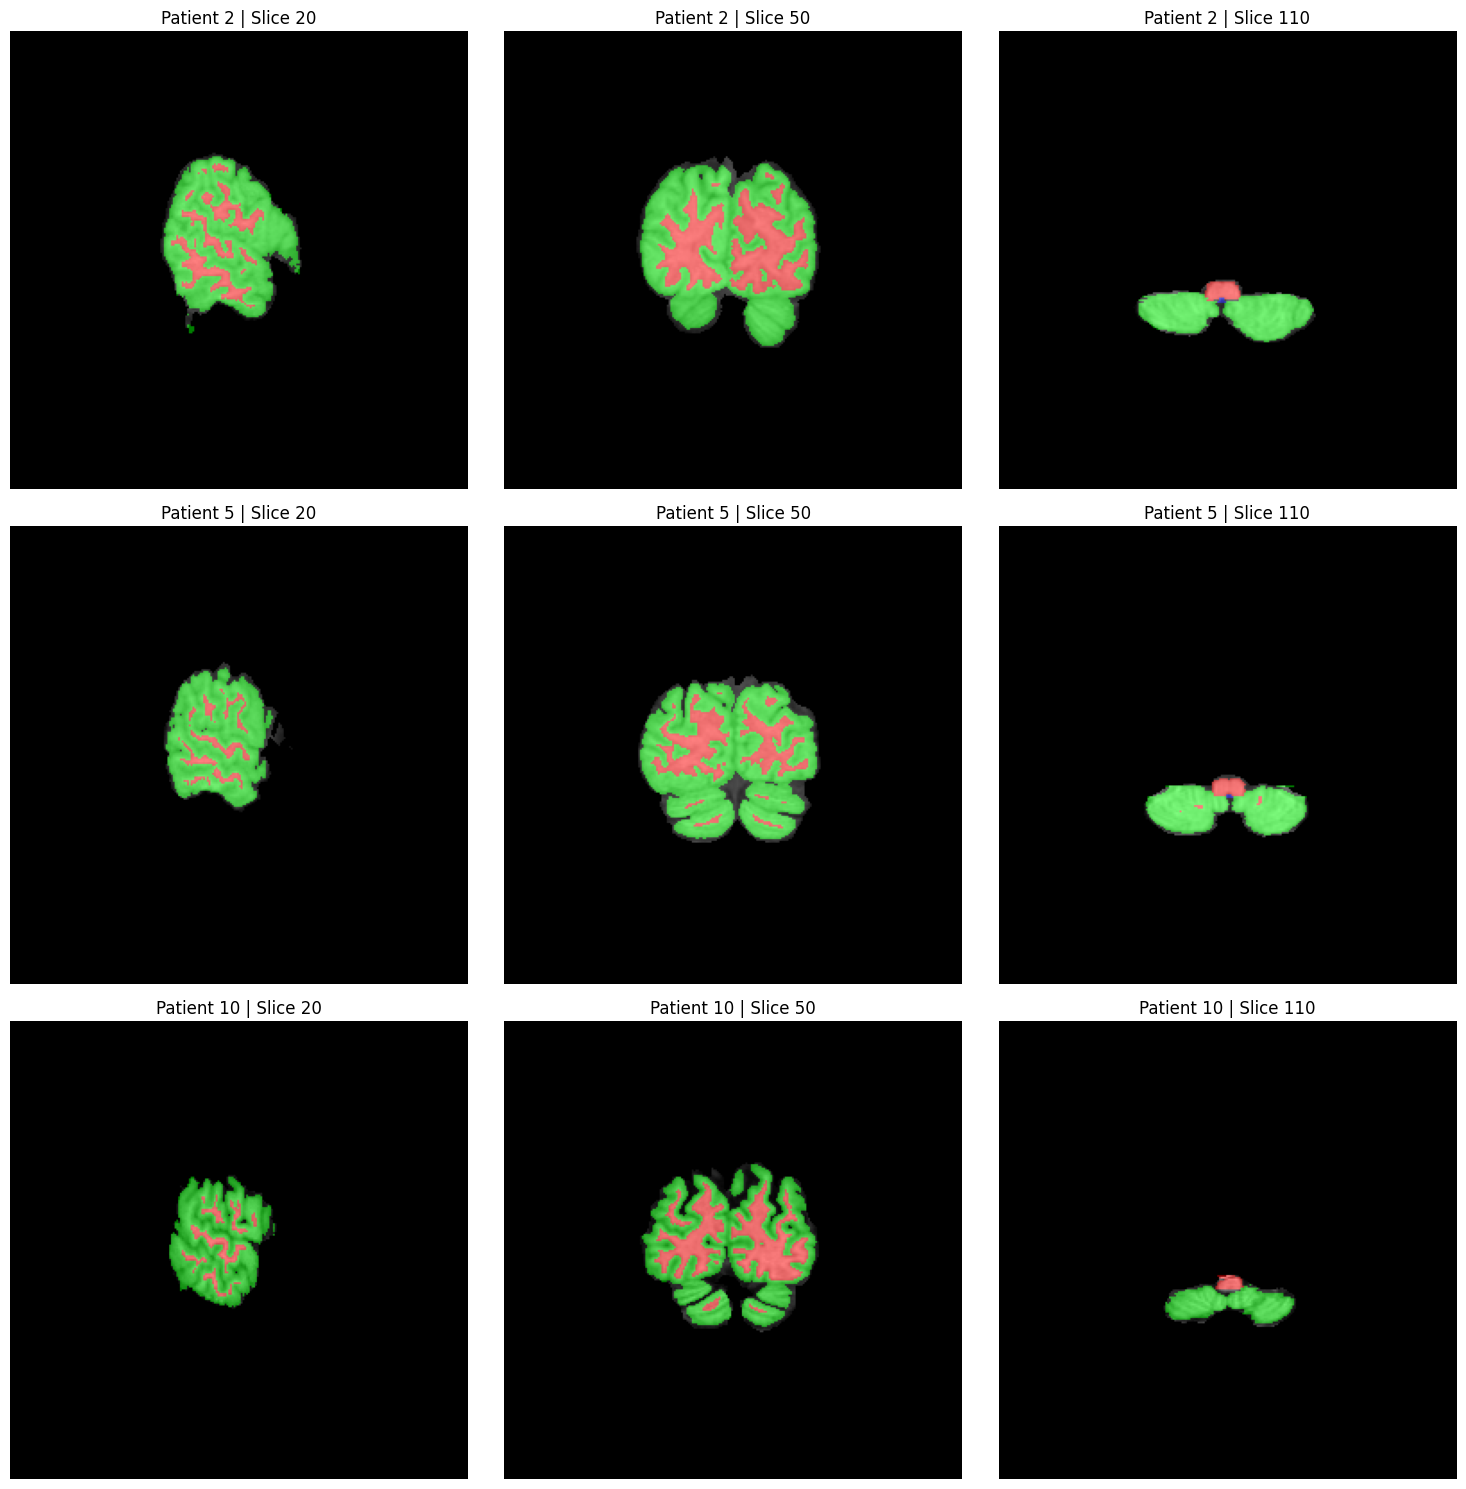

In [6]:
def plot_patients_patch_2x2():
    CLASS_COLORS = {
        0: (0, 0, 0),   # Background
        1: (0, 0, 1),   # CSF
        2: (0, 1, 0),   # WM
        3: (1, 0, 0),   # GM
    }

    def colorize_mask(mask):
        h, w = mask.shape
        rgb = np.zeros((h, w, 3))
        for cls, color in CLASS_COLORS.items():
            rgb[mask == cls] = color
        return rgb

    def plot_slice_2x2(vol_patches, mask_patches, title=''):
        top = np.hstack([vol_patches[0].squeeze().numpy(), vol_patches[1].squeeze().numpy()])
        bottom = np.hstack([vol_patches[2].squeeze().numpy(), vol_patches[3].squeeze().numpy()])
        vol = np.vstack([top, bottom])

        top_mask = np.hstack([mask_patches[0].numpy(), mask_patches[1].numpy()])
        bottom_mask = np.hstack([mask_patches[2].numpy(), mask_patches[3].numpy()])
        mask_rgb = colorize_mask(np.vstack([top_mask, bottom_mask]))

        plt.imshow(vol, cmap='gray')
        plt.imshow(mask_rgb, alpha=0.5)
        plt.title(title)
        plt.axis('off')

    plt.figure(figsize=(15, 15))
    for i, patient_id in enumerate([2, 5, 10]):
        vol, seg = collection_path(patient_id)
        dataset = IBSRPatchDataset(vol, seg)

        slice_indices = [20, 50, 110]

        for j, slice_id in enumerate(slice_indices):
            start_idx = slice_id * 4
            vol_patches = []
            mask_patches = []
            for idx in range(start_idx, start_idx + 4):
                v, m = dataset[idx]
                vol_patches.append(v)
                mask_patches.append(m)

            plt.subplot(3, 3, 1+ i*3 + j)
            plot_slice_2x2(vol_patches, mask_patches, title=f'Patient {patient_id} | Slice {slice_id}')

    plt.tight_layout()
    plt.show()

plot_patients_patch_2x2()


In [7]:
import glob
import random
def train_test_split_files():
    cases = list(range(1,19))
    random.shuffle(cases)
    test = cases[:6]
    train = cases[6:]
    test_volumes = [collection_path(i)[0][0] for i in test]
    test_segments = [collection_path(i)[1][0] for i in test]
    train_volumes = [collection_path(i)[0][0] for i in train]
    train_segments = [collection_path(i)[1][0] for i in train]

    test_data = IBSRPatchDataset(test_volumes, test_segments)
    train_data = IBSRPatchDataset(train_volumes, train_segments)
    return train_data, test_data

In [8]:
import torch.nn as nn
import torch.optim as optim
import math
from torch.utils.data import DataLoader


class Conv1x1ReLU(nn.Module):
    def __init__(self, in_c, out_c, k=1, s=1, p=0):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_c, out_c, kernel_size=k, stride=s, padding=p),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

class Conv3x3ReLU(nn.Module):
    def __init__(self, in_c, out_c, k=3, s=1, p=1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_c, out_c, kernel_size=k, stride=s, padding=p),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

class DoubleConv(nn.Module):
    def __init__(self, in_c, out_c, leg_in, k=1):
        self.in_c = in_c
        self.leg_in = leg_in
        self.out_c = out_c
        super().__init__()
        if k == 1:
            self.c1 = Conv1x1ReLU(in_c + leg_in, out_c)
            self.c2 = Conv1x1ReLU(in_c + leg_in + out_c, out_c)
        else:
            self.c1 = Conv3x3ReLU(in_c + leg_in, out_c)
            self.c2 = Conv3x3ReLU(in_c + leg_in + out_c, out_c)

    def forward(self, leg, x):
        x1 = torch.cat([leg, x], dim=1)
        x = self.c1(x1)
        x = torch.cat([x, x1], dim=1)
        x = self.c2(x)
        return x

class M_Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.ch = [64, 128, 256, 512]

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.up = nn.Upsample(scale_factor=2, mode="nearest")

        self.l1, self.l2 =  nn.ModuleDict(), nn.ModuleDict()
        self.l3, self.l4 = nn.ModuleDict(), nn.ModuleDict()

        self.l1['lc1'] = Conv1x1ReLU(1, self.ch[0])
        self.l1['lc2'] = Conv1x1ReLU(self.ch[0]+1, self.ch[0])

        self.l2['lc'] = DoubleConv(self.ch[0], self.ch[1], 1, k=1)
        self.l3['lc'] = DoubleConv(self.ch[1], self.ch[2], 1, k=1)
        self.l4['lc'] = DoubleConv(self.ch[2], self.ch[3], 1, k=1)

        self.l4['rc'] = Conv3x3ReLU(self.ch[3], self.ch[3])

        self.l3['rc'] = DoubleConv(self.ch[3], self.ch[2], self.ch[2], k=3)
        self.l2['rc'] = DoubleConv(self.ch[2], self.ch[1], self.ch[1], k=3)
        self.l1['rc1'] = DoubleConv(self.ch[1], self.ch[0], self.ch[0], k=3)

        self.l1['rc2'] = nn.Conv2d(sum(self.ch), 4, 1, 1, 0)
    def forward(self, x):
        left1 = x
        left2 = self.pool(left1)
        left3 = self.pool(left2)
        left4 = self.pool(left3)

        #Encoder
        x1 = self.l1['lc1'](x)
        y = torch.cat([x1, left1], dim=1)
        x1 = self.l1['lc2'](y)
        x = self.pool(x1)

        x2 = self.l2['lc'](left2, x)
        x = self.pool(x2)

        x3 = self.l3['lc'](left3, x)
        x = self.pool(x3)

        x = self.l4['lc'](left4, x)

        #Decoder
        side4 = self.l4['rc'](x)
        x = self.up(side4)

        side3 = self.l3['rc'](x3, x)
        x = self.up(side3)

        side2 = self.l2['rc'](x2, x)
        x = self.up(side2)

        x = self.l1['rc1'](x1, x)

        up3 = self.up(side4)
        up2 = self.up(torch.cat([side3, up3], dim=1))
        up1 = self.up(torch.cat([side2, up2], dim=1))

        x = torch.cat([x, up1], dim=1)
        x = self.l1['rc2'](x)

        return x


def lecun_init(m):
    if isinstance(m, nn.Conv2d):
        fan_in, _ = nn.init._calculate_fan_in_and_fan_out(m.weight)
        std = math.sqrt(1.0 / fan_in)
        nn.init.normal_(m.weight, mean=0.0, std=std)
        if m.bias is not None:
            nn.init.zeros_(m.bias)
            
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model = M_Net().to(device)
model.apply(lecun_init)

optimizer = optim.SGD(model.parameters(), lr=0.0001, momentum=0.9)
criterion = nn.CrossEntropyLoss()

In [9]:
batch_size = 1
train_dataset, test_dataset = train_test_split_files()
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


Loading and processing dataset (with rotation)...
Dataset loaded. Total patches: 3264
Loading and processing dataset (with rotation)...
Dataset loaded. Total patches: 6528


Epoch 1/10: 100%|██████████████████████████████████████████████████████| 6528/6528 [02:42<00:00, 40.07it/s, loss=0.1354]



================ Epoch 1 Summary ================
Train Loss: 0.0571 | Val Loss: 0.1171

 BG | Dice: 0.9970 | IoU: 0.9941 | Prec: 0.9970 | Rec: 0.9971
CSF | Dice: 0.2264 | IoU: 0.1276 | Prec: 0.6265 | Rec: 0.1381
 WM | Dice: 0.7633 | IoU: 0.6172 | Prec: 0.6360 | Rec: 0.9543
 GM | Dice: 0.1802 | IoU: 0.0990 | Prec: 0.9320 | Rec: 0.0997

Macro Dice (excl. BG): 0.3900
------------------------------------------------------------


Epoch 2/10: 100%|██████████████████████████████████████████████████████| 6528/6528 [02:42<00:00, 40.22it/s, loss=0.1085]



================ Epoch 2 Summary ================
Train Loss: 0.0546 | Val Loss: 0.0837

 BG | Dice: 0.9970 | IoU: 0.9940 | Prec: 0.9965 | Rec: 0.9974
CSF | Dice: 0.2578 | IoU: 0.1480 | Prec: 0.6932 | Rec: 0.1584
 WM | Dice: 0.8138 | IoU: 0.6860 | Prec: 0.7171 | Rec: 0.9405
 GM | Dice: 0.5732 | IoU: 0.4017 | Prec: 0.9476 | Rec: 0.4108

Macro Dice (excl. BG): 0.5482
------------------------------------------------------------


Epoch 3/10: 100%|██████████████████████████████████████████████████████| 6528/6528 [02:42<00:00, 40.22it/s, loss=0.0004]



================ Epoch 3 Summary ================
Train Loss: 0.0529 | Val Loss: 0.0562

 BG | Dice: 0.9970 | IoU: 0.9941 | Prec: 0.9968 | Rec: 0.9973
CSF | Dice: 0.4064 | IoU: 0.2550 | Prec: 0.5349 | Rec: 0.3276
 WM | Dice: 0.8516 | IoU: 0.7416 | Prec: 0.8777 | Rec: 0.8271
 GM | Dice: 0.8314 | IoU: 0.7114 | Prec: 0.7905 | Rec: 0.8767

Macro Dice (excl. BG): 0.6964
------------------------------------------------------------


... (10 outputs left out)

Epoch 9/10: 100%|██████████████████████████████████████████████████████| 6528/6528 [02:41<00:00, 40.35it/s, loss=0.0258]



================ Epoch 9 Summary ================
Train Loss: 0.0483 | Val Loss: 0.0536

 BG | Dice: 0.9972 | IoU: 0.9945 | Prec: 0.9973 | Rec: 0.9972
CSF | Dice: 0.4836 | IoU: 0.3189 | Prec: 0.5552 | Rec: 0.4284
 WM | Dice: 0.8661 | IoU: 0.7638 | Prec: 0.8696 | Rec: 0.8626
 GM | Dice: 0.8390 | IoU: 0.7227 | Prec: 0.8282 | Rec: 0.8502

Macro Dice (excl. BG): 0.7296
------------------------------------------------------------


Epoch 10/10: 100%|█████████████████████████████████████████████████████| 6528/6528 [02:42<00:00, 40.25it/s, loss=0.0681]



================ Epoch 10 Summary ================
Train Loss: 0.0476 | Val Loss: 0.0557

 BG | Dice: 0.9972 | IoU: 0.9944 | Prec: 0.9985 | Rec: 0.9959
CSF | Dice: 0.4573 | IoU: 0.2965 | Prec: 0.5971 | Rec: 0.3706
 WM | Dice: 0.8724 | IoU: 0.7737 | Prec: 0.8395 | Rec: 0.9080
 GM | Dice: 0.8358 | IoU: 0.7179 | Prec: 0.8623 | Rec: 0.8109

Macro Dice (excl. BG): 0.7218
------------------------------------------------------------


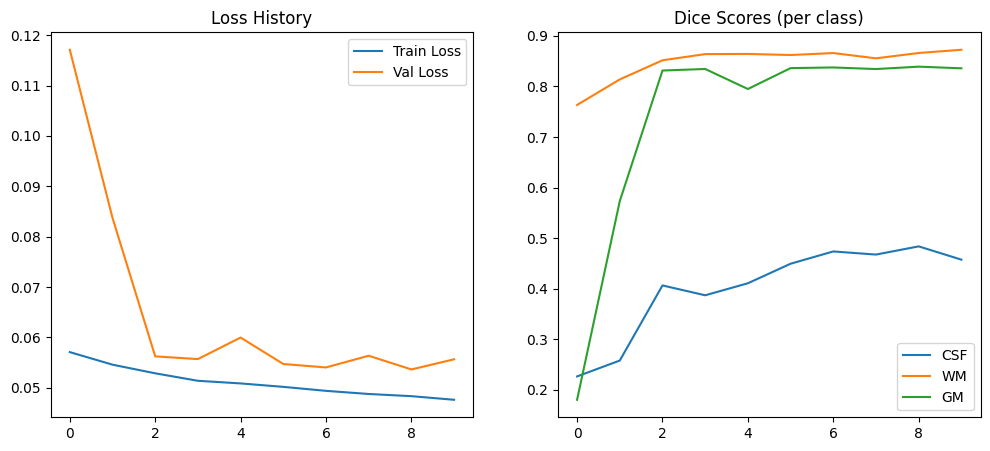

In [11]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt

class Metrics:
    def __init__(self, num_classes: int):
        self.num_classes = num_classes
        self.reset()

    def reset(self):
        self.tp = torch.zeros(self.num_classes, dtype=torch.float64)
        self.fp = torch.zeros(self.num_classes, dtype=torch.float64)
        self.fn = torch.zeros(self.num_classes, dtype=torch.float64)

    @torch.no_grad()
    def update(self, preds, targets):
        for c in range(self.num_classes):
            pred_c = (preds == c)
            target_c = (targets == c)
            self.tp[c] += torch.sum(pred_c & target_c).item()
            self.fp[c] += torch.sum(pred_c & (~target_c)).item()
            self.fn[c] += torch.sum((~pred_c) & target_c).item()

    def compute(self, eps=1e-6):
        dice = (2 * self.tp) / (2 * self.tp + self.fp + self.fn + eps)
        jaccard = self.tp / (self.tp + self.fp + self.fn + eps)
        precision = self.tp / (self.tp + self.fp + eps)
        recall = self.tp / (self.tp + self.fn + eps)
        return {"dice": dice, "jaccard": jaccard, "precision": precision, "recall": recall}

num_epochs = 10
num_classes = 4
class_names = ['BG', 'CSF', 'WM', 'GM']
metrics_tracker = Metrics(num_classes=num_classes)

train_losses, val_losses = [], []
dice_history = {c: [] for c in range(num_classes)}

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}", ncols=120)

    for i, (inputs, labels) in enumerate(pbar, start=1):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        pbar.set_postfix(loss=f"{loss.item():.4f}")

    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)

    model.eval()
    val_running_loss = 0.0
    metrics_tracker.reset()

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            val_running_loss += criterion(outputs, labels).item()

            preds = torch.argmax(outputs, dim=1)
            metrics_tracker.update(preds.cpu(), labels.cpu())

    epoch_val_loss = val_running_loss / len(test_loader)
    val_losses.append(epoch_val_loss)
    
    results = metrics_tracker.compute()

    for c in range(num_classes):
        dice_history[c].append(results["dice"][c].item())

    print(f"\n================ Epoch {epoch+1} Summary ================")
    print(f"Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}\n")

    for c in range(num_classes):
        print(
            f"{class_names[c]:>3} | "
            f"Dice: {results['dice'][c]:.4f} | "
            f"IoU: {results['jaccard'][c]:.4f} | "
            f"Prec: {results['precision'][c]:.4f} | "
            f"Rec: {results['recall'][c]:.4f}"
        )
    
    macro_dice = results["dice"][1:].mean().item()
    print(f"\nMacro Dice (excl. BG): {macro_dice:.4f}")
    print("-" * 60)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.title('Loss History'); plt.legend()

plt.subplot(1, 2, 2)
for c in range(1, num_classes):
    plt.plot(dice_history[c], label=class_names[c])
plt.title('Dice Scores (per class)'); plt.legend()
plt.show()

Loading and processing dataset (with rotation)...
Dataset loaded. Total patches: 544


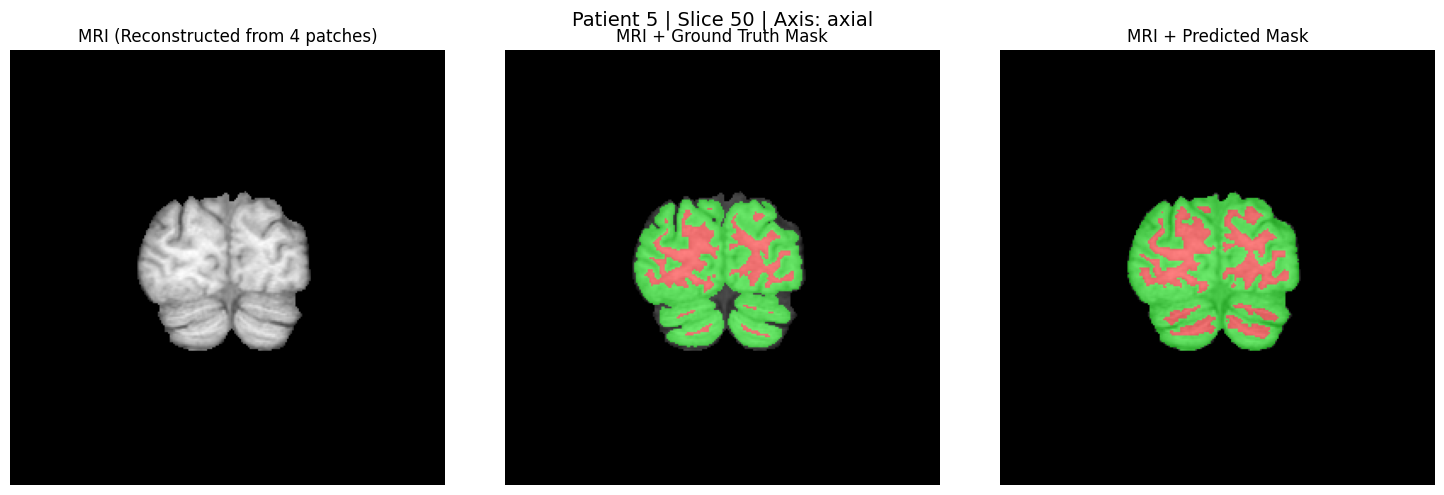

In [18]:

def plot_random_patient_patch_prediction(
    model,
    axis='axial',
    device='cuda:0'
):
    model.eval()

    CLASS_COLORS = {
        0: (0, 0, 0),   # Background
        1: (0, 0, 1),   # CSF
        2: (0, 1, 0),   # WM
        3: (1, 0, 0),   # GM
    }

    def colorize_mask(mask):
        h, w = mask.shape
        rgb = np.zeros((h, w, 3))
        for cls, color in CLASS_COLORS.items():
            rgb[mask == cls] = color
        return rgb

    def merge_2x2(patches):
        top = np.hstack([patches[0], patches[1]])
        bottom = np.hstack([patches[2], patches[3]])
        return np.vstack([top, bottom])

    patient_id = random.choice([2, 5, 10])
    vol, seg = collection_path(patient_id)
    dataset = IBSRPatchDataset(vol, seg)

    slice_id = random.choice([20, 50, 110])
    start_idx = slice_id * 4

    vol_patches = []
    gt_patches = []
    pred_patches = []

    for idx in range(start_idx, start_idx + 4):
        v, m = dataset[idx]

        with torch.no_grad():
            inp = v.unsqueeze(0).to(device)
            out = model(inp)
            pred = torch.argmax(out, dim=1)

        vol_patches.append(v.squeeze().numpy())
        gt_patches.append(m.numpy())
        pred_patches.append(pred.squeeze().cpu().numpy())

    vol_img = merge_2x2(vol_patches)
    gt_mask = colorize_mask(merge_2x2(gt_patches))
    pred_mask = colorize_mask(merge_2x2(pred_patches))

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(vol_img, cmap='gray')
    plt.title('MRI (Reconstructed from 4 patches)')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(vol_img, cmap='gray')
    plt.imshow(gt_mask, alpha=0.5)
    plt.title('MRI + Ground Truth Mask')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(vol_img, cmap='gray')
    plt.imshow(pred_mask, alpha=0.5)
    plt.title('MRI + Predicted Mask')
    plt.axis('off')

    plt.suptitle(
        f'Patient {patient_id} | Slice {slice_id} | Axis: {axis}',
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

plot_random_patient_patch_prediction(model)

In [19]:
def count_model_parameters(model):
    trainable = 0
    non_trainable = 0

    for param in model.parameters():
        if param.requires_grad:
            trainable += param.numel()
        else:
            non_trainable += param.numel()

    total = trainable + non_trainable

    print(f"Trainable parameters     : {trainable:,}")
    print(f"Non-trainable parameters : {non_trainable:,}")
    print(f"Total parameters         : {total:,}")

count_model_parameters(model)

Trainable parameters     : 8,479,620
Non-trainable parameters : 0
Total parameters         : 8,479,620
